In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from keras.layers import Dense
from keras.models import Sequential

In [2]:
X,y = make_moons(n_samples=250,noise=0.2,random_state=42)

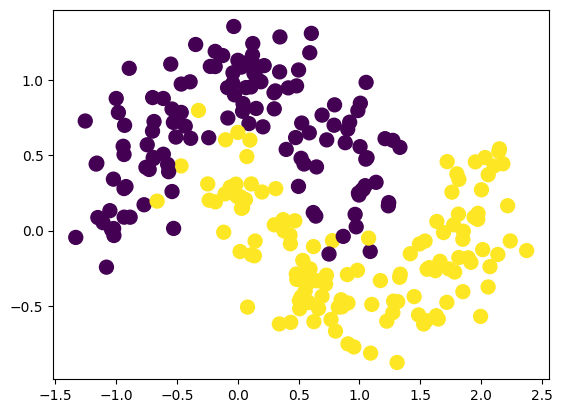

In [3]:
plt.scatter(X[:,0],X[:,1],c=y,s=100)
plt.show()

In [4]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [5]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [6]:
old_weights = model.get_weights()[0]

In [7]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [8]:
model.fit(X_train,y_train,epochs=100,batch_size=10)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 21ms/step - accuracy: 0.5100 - loss: 1.1444
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5900 - loss: 0.7116
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7200 - loss: 0.5609
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7450 - loss: 0.4900
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7700 - loss: 0.4511
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7650 - loss: 0.4132
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7950 - loss: 0.3925
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8050 - loss: 0.3544
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8550 - loss: 0.3298
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8700 - loss: 0.2953
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9000 - loss: 0.3282
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accu

In [9]:
new_weights = model.get_weights()[0]

In [10]:
model.optimizer.get_config()['learning_rate']

0.0010000000474974513

In [11]:
gradient = (old_weights - new_weights)/0.001
percent_change = abs(100*(old_weights-new_weights)/old_weights)
gradient

array([[ -37.354527,   93.38757 ,   22.928177, -169.65614 ,  -95.85401 ,
         -85.48706 ,  -57.902737,  -66.61747 , -107.0764  , -202.35089 ],
       [  13.438761,  -68.42679 ,  446.36526 , -175.73041 , -130.47054 ,
        -174.96994 ,  208.82635 ,   68.219826, -185.46939 ,   -9.963751]],
      dtype=float32)

In [17]:
old_weights

array([[-0.5903752 , -0.47159407,  0.59715086,  0.53819126,  0.34874207,
        -0.51637506,  0.08354855, -0.02381378,  0.2915945 , -0.16945934],
       [ 0.39339358, -0.53170794, -0.27050656, -0.02081281, -0.20310885,
        -0.19431281, -0.04984421, -0.12137938,  0.00197417,  0.6857299 ]],
      dtype=float32)

In [16]:
new_weights

array([[-0.55302066, -0.56498164,  0.5742227 ,  0.7078474 ,  0.44459608,
        -0.430888  ,  0.14145128,  0.04280369,  0.3986709 ,  0.03289156],
       [ 0.37995481, -0.46328115, -0.71687186,  0.15491761, -0.0726383 ,
        -0.01934287, -0.25867057, -0.1895992 ,  0.18744357,  0.6956937 ]],
      dtype=float32)

In [12]:
percent_change

array([[6.32725239e+00, 1.98025341e+01, 3.83959556e+00, 3.15233955e+01,
        2.74856472e+01, 1.65552273e+01, 6.93042984e+01, 2.79743347e+02,
        3.67209969e+01, 1.19409706e+02],
       [3.41611099e+00, 1.28692436e+01, 1.65010895e+02, 8.44337830e+02,
        6.42367630e+01, 9.00455017e+01, 4.18958160e+02, 5.62038002e+01,
        9.39482520e+03, 1.45301390e+00]], dtype=float32)

In [13]:
loss_function = tf.keras.losses.BinaryCrossentropy()

with tf.GradientTape() as tape:

    predictions = model(X_train[:32], training=True)

    loss = loss_function(
        tf.cast(y_train[:32], tf.float32),
        predictions
    )

gradients = tape.gradient(
    loss,
    model.trainable_variables
)

for i, layer in enumerate(model.layers):

    kernel_gradient = gradients[2*i]

    gradient_norm = tf.norm(kernel_gradient)

    print(layer.name, gradient_norm.numpy())

dense 0.70992666
dense_1 1.0795099
dense_2 0.9089665
dense_3 0.9752
dense_4 0.6689703
dense_5 0.5415504
dense_6 0.32779843
dense_7 0.18368201
dense_8 0.10295823
dense_9 0.06984007
dense_10 0.08073213


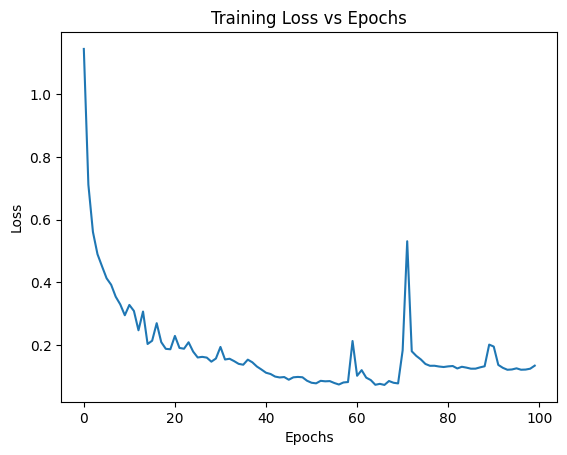

In [14]:
plt.plot(model.history.history['loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training Loss vs Epochs')
plt.show()

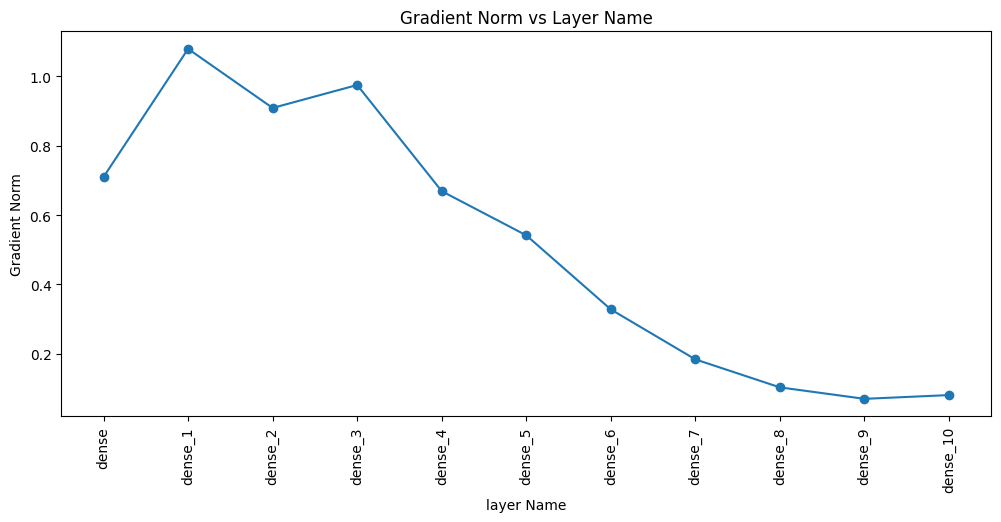

In [15]:
layers_names = []
gradient_values = []

for i,layer in enumerate(model.layers):
  kernel_gradient = gradients[2*i]
  gradient_norm = tf.norm(kernel_gradient)

  layers_names.append(layer.name)
  gradient_values.append(gradient_norm.numpy())
plt.figure(figsize=(12,5))
plt.plot(layers_names,gradient_values,marker='o')
plt.xlabel('layer Name')
plt.ylabel('Gradient Norm')
plt.title('Gradient Norm vs Layer Name')
plt.xticks(rotation=90)
plt.show()